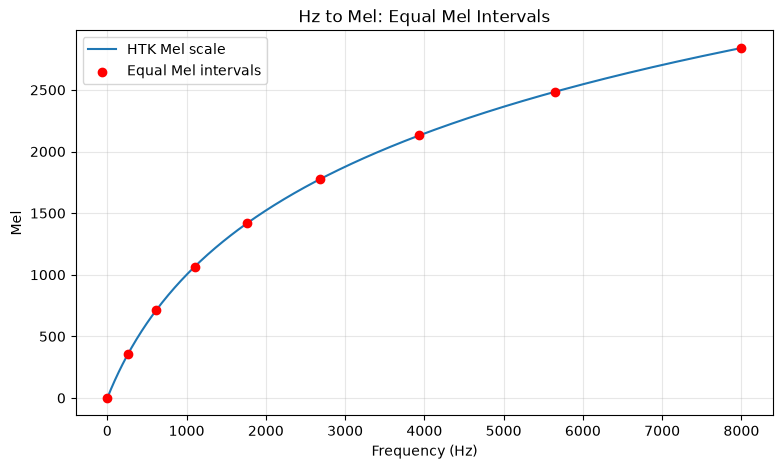

等Mel点对应的Hz位置:
[   0.   259.2  614.3 1101.  1767.8 2681.5 3933.6 5649.2 8000. ]

相邻点的Hz间隔:
[ 259.2  355.1  486.6  666.8  913.7 1252.  1715.6 2350.8]


In [1]:
import numpy as np
import matplotlib.pyplot as plt

#1.生成0-8000Hz的频率点
hz = np.linspace(0,8000,500)

#2.HTK Hz->Mel
mel = 2595 * np.log10(1 + hz/700)

#3.在Mel坐标上均匀选取9个点
mel_points = np.linspace(mel[0],mel[-1],9)

#4.通过HTK反变换得到对应Hz位置
hz_points = 700 * (10 ** (mel_points / 2595) - 1)

#5. 绘图
fig, ax = plt.subplots(figsize=(9,5))

ax.plot(hz,mel,label="HTK Mel scale")
ax.scatter(
    hz_points,
    mel_points,
    color="red",
    zorder=3,
    label="Equal Mel intervals"
)

ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Mel")
ax.set_title("Hz to Mel: Equal Mel Intervals")
ax.grid(alpha=0.3)
ax.legend()

plt.show()

# 6. 比较对应的Hz间隔
print("等Mel点对应的Hz位置:")
print(np.round(hz_points, 1))

print("\n相邻点的Hz间隔:")
print(np.round(np.diff(hz_points), 1))

In [2]:
#手写与librosa函数对照
import sys
from pathlib import Path
import importlib

import numpy as np
import librosa

root = Path.cwd().resolve()
if root.name.lower() == "notebooks":
    root = root.parent

if str(root) not in sys.path:
    sys.path.insert(0, str(root))

import src.features as features

# 在Notebook中重新读取修改后的features.py
importlib.reload(features)

hz = np.array([0,100,500,1000,2000,8000])

#HTK对照
ours_htk = features.hz_to_mel(hz,scale="htk")
lib_htk = librosa.hz_to_mel(hz,htk=True)

#Slaney对照
ours_slaney = features.hz_to_mel(hz,scale="slaney")
lib_slaney = librosa.hz_to_mel(hz,htk=False)

print("HTK 最大误差:", np.max(np.abs(ours_htk - lib_htk)))
print("Slaney 最大误差:", np.max(np.abs(ours_slaney - lib_slaney)))

print("\nHz:", hz)
print("HTK Mel:", np.round(ours_htk, 3))
print("Slaney Mel:", np.round(ours_slaney, 3))

assert np.allclose(ours_htk, lib_htk, atol=1e-9)
assert np.allclose(ours_slaney, lib_slaney, atol=1e-9)

assert features.hz_to_mel(0) == 0.0

print("\nHz → Mel 两套约定均通过对照")

HTK 最大误差: 0.0
Slaney 最大误差: 3.552713678800501e-15

Hz: [   0  100  500 1000 2000 8000]
HTK Mel: [   0.     150.489  607.446  999.986 1521.36  2840.023]
Slaney Mel: [ 0.     1.5    7.5   15.    25.082 45.246]

Hz → Mel 两套约定均通过对照


In [3]:
#异常处理
for value in [-100,float("nan"),float("inf")]:
    try:
        features.hz_to_mel(value)
    except ValueError:
        print(f"{value}:正确拒绝")
    else:
        raise AssertionError(f"{value}: 未拒绝异常输入")

-100:正确拒绝
nan:正确拒绝
inf:正确拒绝


原始功率: [1.e+00 1.e-02 1.e-04 0.e+00]
对数压缩后(dB): [   0.  -20.  -40. -100.]


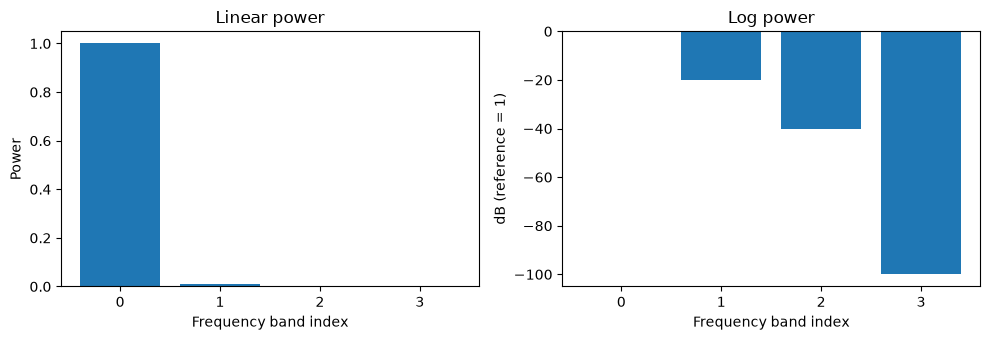

In [4]:
#验证动态范围压缩
import numpy as np
import matplotlib.pyplot as plt

power = np.array([1.0,1e-2,1e-4,0.0])

eps = 1e-10
log_power_db = 10 * np.log10(np.maximum(power, eps))

print("原始功率:", power)
print("对数压缩后(dB):", log_power_db)

fig,axes = plt.subplots(1,2,figsize=(10,3.5))

axes[0].bar(range(len(power)), power)
axes[0].set_title("Linear power")
axes[0].set_ylabel("Power")

axes[1].bar(range(len(power)), log_power_db)
axes[1].set_title("Log power")
axes[1].set_ylabel("dB (reference = 1)")

for ax in axes:
    ax.set_xlabel("Frequency band index")
    ax.set_xticks(range(len(power)))

fig.tight_layout()
plt.show()